# 2 · Logistic regression

```{math}
p = \sigma(w x + b),\qquad \sigma(z) = \frac{1}{1 + e^{-z}}
```

**Family:** linear models · **Task:** classification

The video bends the yellow regression line into an S-curve that runs from the blue
points at $y=0$ to the red points at $y=1$. The model is still linear inside
$\sigma$; it is trained by minimising the log-loss (binary cross-entropy)

```{math}
L(w,b) = -\frac1n\sum_i \big[y_i\log p_i + (1-y_i)\log(1-p_i)\big],\qquad
\partial_w L = \frac1n\sum_i (p_i - y_i)\,x_i,\quad \partial_b L = \frac1n\sum_i (p_i - y_i).
```

## Imports

`ml8` is the book's own package; [The sample data](00_sample_data.ipynb) explains how it is
imported. This chapter uses:

| File | What this chapter uses |
|---|---|
| `ml8/data.py` | `data.logistic_data`: the 1-D logistic sample<br>`data.moons_arrays`: two-moons train and test arrays (`X_train, y_train, X_test, y_test`) |
| `ml8/scratch.py` | `scratch.logistic_gd`: gradient descent for logistic regression<br>`scratch.sigmoid`: the function $\sigma(z)$ |
| `ml8/models.py` | `models.logistic_2d`: a scikit-learn `LogisticRegression` for the two-moons data<br>`models.LOGISTIC_RECORD`: the gradient-descent steps to record |
| `ml8/plotting.py` | `P.plot_surface`: draws a decision surface and the points<br>`P.point_colors`: colours points by class<br>the palette (`P.FG`, `P.YELLOW`) |

In [1]:
# ml8 sits one folder above notebooks/, so put that folder on Python's search path
import sys
sys.path.insert(0, "..")

# Installed packages
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

# The book's own modules
from ml8 import data              # ml8/data.py: the seeded sample datasets
from ml8 import models            # ml8/models.py: shared model settings
from ml8 import plotting as P     # ml8/plotting.py: colours and plot helpers
from ml8 import scratch           # ml8/scratch.py: the from-scratch formulas

P.use_style()  # the dark style used by every figure
pd.set_option("display.precision", 4)

In [2]:
lg = data.logistic_data()
x, y = lg.x.to_numpy(), lg.y.to_numpy()
(w, b), hist = scratch.logistic_gd(x, y, record=set(models.LOGISTIC_RECORD))
gd = pd.DataFrame(hist, columns=["iter", "w", "b", "logloss", "acc"])
gd

,iter,w,b,logloss,acc
0,0,0.0000,0.0000,0.6931,0.3333
1,5,0.0445,-0.1112,0.6682,0.5833
2,10,0.0636,-0.2227,0.6470,0.7167
3,20,0.1000,-0.4340,0.6088,0.8500
4,40,0.1658,-0.8153,0.5465,0.9333
5,80,0.2753,-1.4450,0.4612,0.9000
6,150,0.4190,-2.2638,0.3784,0.9000
7,300,0.6224,-3.4082,0.3019,0.9000
8,600,0.8615,-4.7363,0.2499,0.9000
9,1000,1.0528,-5.7889,0.2256,0.9000


## Check against scikit-learn

scikit-learn regularises by default, so we switch the penalty off to compare like with
like. Plain gradient descent is slow on this unscaled feature, so after 8,000 steps it
is close to, but not exactly at, the optimum.

In [3]:
sk = LogisticRegression(C=np.inf).fit(x[:, None], y)
pd.DataFrame({"w": [w, sk.coef_[0, 0]], "b": [b, sk.intercept_[0]], "decision boundary x = -b/w": [-b / w, -sk.intercept_[0] / sk.coef_[0, 0]]},
             index=["gradient descent", "scikit-learn"])

,w,b,decision boundary x = -b/w
gradient descent,1.7319,-9.5016,5.4862
scikit-learn,1.8170,-9.9670,5.4853


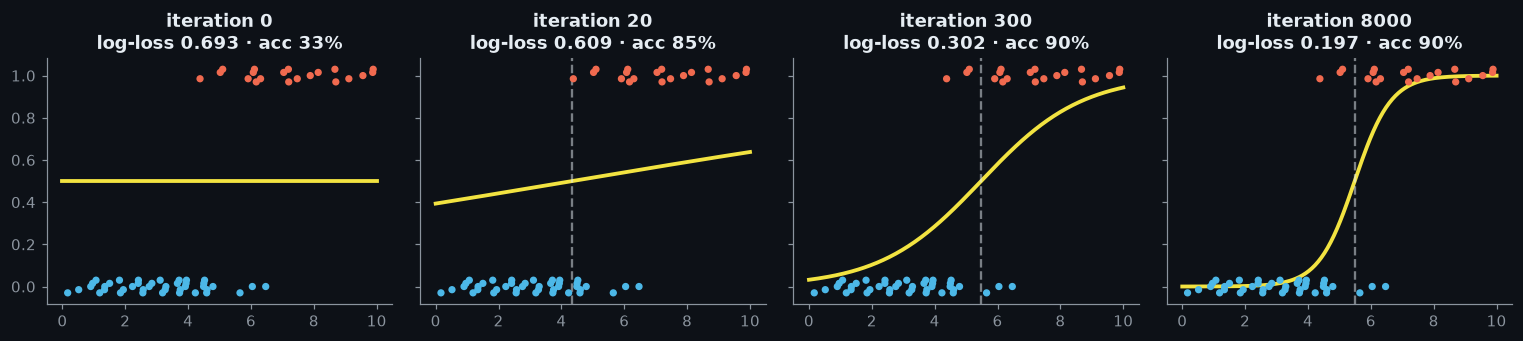

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
xs = np.linspace(0, 10, 200)
jit = ((lg.id % 5) - 2) * 0.015
for ax, it in zip(axes, [0, 20, 300, 8000]):
    r = gd[gd.iter == it].iloc[0]
    ax.scatter(x, y + jit, s=14, c=P.point_colors(y), zorder=3)
    ax.plot(xs, scratch.sigmoid(r.w * xs + r.b), c=P.YELLOW, lw=2.5)
    if r.w > 0 and 0 < -r.b / r.w < 10:
        ax.axvline(-r.b / r.w, ls="--", c=P.FG, alpha=0.5)
    ax.set_title(f"iteration {it}\nlog-loss {r.logloss:.3f} · acc {r.acc:.0%}")
plt.tight_layout()

## The limit: a straight boundary

In two dimensions the boundary $\{x : w^\top x + b = 0\}$ is a straight line. On the
two-moons data that leaves both tips of the moons on the wrong side, which is the
motivation for every non-linear model in the rest of the book.

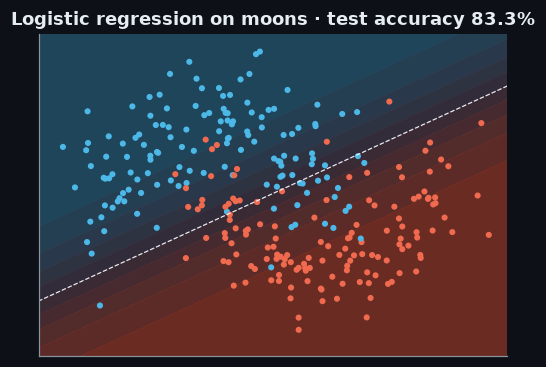

In [5]:
Xtr, ytr, Xte, yte = data.moons_arrays()
clf = models.logistic_2d().fit(Xtr, ytr)
fig, ax = plt.subplots(figsize=(5.5, 3.8))
P.plot_surface(ax, clf, Xtr, ytr, title=f"Logistic regression on moons · test accuracy {clf.score(Xte, yte):.1%}");

**Try it:** add the features $x_1^2, x_2^2, x_1x_2$ (`sklearn.preprocessing.PolynomialFeatures`)
and refit. The model stays linear in its parameters, but the boundary can now curve.